# Inverse Problems 2026 - Exercise 1 (home exercises)

Return by **Fri 6.11.2026 at 23:59** in Moodle! You can ask for help with these exercises in the exercise session the same day (10:00, room 7334).

The returned exercises should be renamed `Exercise01_lastname_firstname.ipynb` and contain your solutions in clear and readable manner and format. The programming exercises need to be runnable with minimal effort. If you find markdown too cumbersome for writing the necessary math, you can attach **a single extra pdf-file** for the theoretical exercises and denote it `Exercise01_lastname_firstname.pdf`.

___
## Task 1
The following Python code reproduces the results for the inverse heat distribution problem obtained in the first set of lecture notes. Modify it for the following setup.

Use the end time $T = 0.05$. Whatâ€™s the rank of $A$ now? Add similar noise to the observation with standard deviation $0.001$
as in the slides. How many singular values can be used before reconstruction becomes unstable? Include a plot of your solution in the answer.

A is 99 x 99; numerical rank = 26
Many of the singular values ​​of this matrix are extremely small. Using its default tolerance, NumPy treats these very small values ​​as numerically zero and reports a rank of 26.


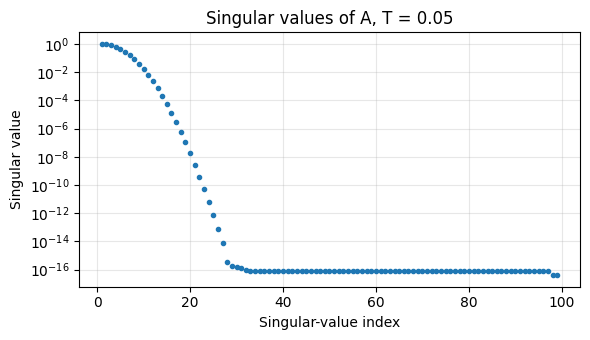

In [76]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la

T = 0.05
N = 100
h = np.pi / N
# Finite-difference Laplacian with insulated (Neumann) endpoints.
B = np.diag(np.ones(N - 2), k=-1) - 2 * np.eye(N - 1) + np.diag(np.ones(N - 2), k=1)
B[0, 0] = -1
B[-1, -1] = -1
B = B / h**2

# Step 1: Building a Heat Diffusion Model
A = la.expm(T * B) # Matrix exponential
[U, Svals, Vt] = la.svd(A) # Singular Value Decomposition

# Step 2: Calculating the Rank of a Matrix
numerical_rank = np.linalg.matrix_rank(A) 
print(f'A is {A.shape[0]} x {A.shape[1]}; numerical rank = {numerical_rank}')
print(f'Many of the singular values ​​of this matrix are extremely small. Using its default tolerance, NumPy treats these very small values ​​as numerically zero and reports a rank of {numerical_rank}.')

# Step 2.1: Visualizing the Singular Values
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(np.arange(1, N), Svals, '.')
ax.set(xlabel='Singular-value index', ylabel='Singular value', title='Singular values of A, T = 0.05')
ax.grid(alpha=0.3)
fig.tight_layout()

In [77]:
# Step 3: Generation of observed data with noise
# This stage is the "forward problem." In other words, given the initial distribution, we calculated the temperature after diffusion.
x = np.arange(1, N) * h
a, b1, b2 = 40 * np.pi / 30, -8 / 3, 20 / 3
peak = 35
f = np.maximum(np.concatenate([a * x[:peak] + b1, -a * x[peak:] + b2]), 0)
w = A @ f # Data

# To simulate this situation, we add noise.
sigma = 0.001
rng_task1 = np.random.default_rng(2026)
w_noisy = w + sigma * rng_task1.standard_normal(w.size)

Since $B$ is symmetric, the eigenvalues of $A=\exp(TB)$ are $\exp(T\lambda_j(B))>0$. Thus $A$ has **exact rank 99**. In double precision, NumPy reports **numerical rank 26** (default tolerance about $2.2\times10^{-14}$); this depends on the rank tolerance.

To avoid amplifying noise through small singular values, reconstruct with the first $k$ terms of the truncated SVD, $f_k=\sum_{j=1}^k (u_j^\top w^\delta/s_j)v_j$. As in the lecture notes (Section 2.2), select the smallest $k$ whose data residual is at most $1.1\sigma\sqrt{99}$, the expected noise norm with a small margin.

Discrepancy threshold = 0.01094; selected k = 10
k =  9: residual = 0.01351, relative error = 10.1%
k = 10: residual = 0.00911, relative error = 5.9%
k = 12: residual = 0.00904, relative error = 9.4%
k = 15: residual = 0.00899, relative error = 194.1%


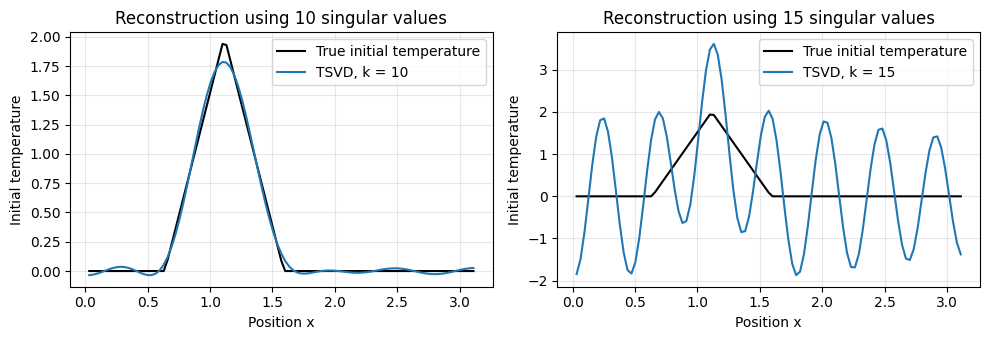

In [78]:
# Step 4: Reconstruction using Truncated SVD
ks = np.arange(1, 21)
reconstructions = []
residuals = []
# Retain only the k largest singular components.
for k in ks:
    fk = Vt[:k, :].T @ ((U[:, :k].T @ w_noisy) / Svals[:k])
    reconstructions.append(fk)
    residuals.append(la.norm(A @ fk - w_noisy))

# Step 5: Selecting the best k
# Using Morozov Discrepancy Principle. Expected noise norm, with a small margin for the discrepancy rule.
threshold = 1.1 * sigma * np.sqrt(w.size)
k_selected = int(ks[np.flatnonzero(np.array(residuals) <= threshold)[0]])
print(f'Discrepancy threshold = {threshold:.5f}; selected k = {k_selected}')
# The known initial state is used only to assess the reconstructions.
for k in (9, 10, 12, 15):
    error = la.norm(reconstructions[k - 1] - f) / la.norm(f)
    print(f'k = {k:2d}: residual = {residuals[k - 1]:.5f}, relative error = {error:.1%}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True)
for ax, k in zip(axes, (k_selected, 15)):
    ax.plot(x, f, 'k', label='True initial temperature')
    ax.plot(x, reconstructions[k - 1], label=f'TSVD, k = {k}')
    ax.set(xlabel='Position x', ylabel='Initial temperature', title=f'Reconstruction using {k} singular values')
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()

**Answer.** The exact rank is **99**, while the numerical rank is **26** at NumPy's default tolerance. For this reproducible noise sample, the discrepancy principle selects **10 singular values**. The reconstruction has about **5.9%** relative error at $k=10$; the error rises to about **9.4%** at $k=12$ and **194%** at $k=15$. Thus approximately **10** singular values can be used reliably here, and the reconstruction becomes clearly unstable by 15. The exact cutoff depends on the noise realization and the chosen stability criterion.

___
In the following exercises we learn to solve 1D deconvolution problems. The direct problem is defined as

$$ g(x) = Af(x) = \int k(x âˆ’y)f(y)dy, $$

where the domain of integration is a unit interval. As you might remember from Functional Analysis the mapping $A : C[0,1) \to C[0,1)$ is compact and, therefore, the inverse problem is ill-posed.
___

## Task 2
Run the following code cell. Plot the reconstructed vectors `recn1`, `recn2` and `recn3`, then explain how each is obtained. How does an _inverse crime_ affect the reconstructions?

Relative errors: recn1 = 4.93e-16, recn2 = 59.2%
59.2% for recn2. This error level indicates that direct inversion of the noisy data failed to produce a suitable reconstruction. Thus, 
while `recn1` yielded an error of nearly zero, `recn2` was severely affected by noise.


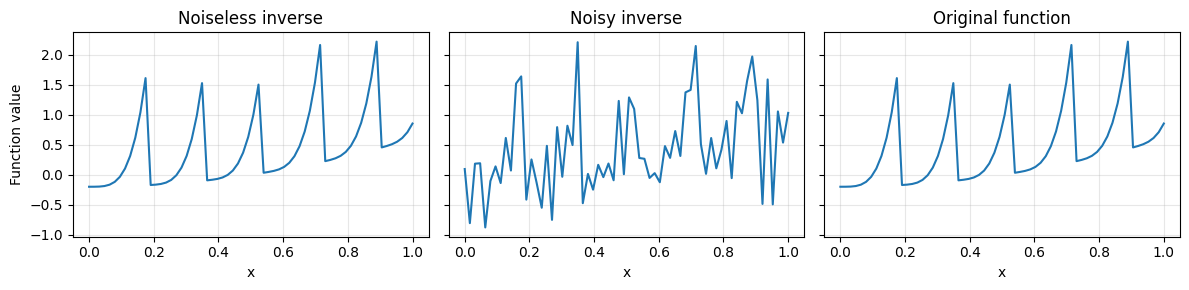

In [ ]:
# Step 1: Constructing the initial signal and the convolution matrix
rng = np.random.default_rng(42)
n = 64
xx = np.linspace(0, 1, n)

def fun(x):
    return 0.05*((4*x)**2 - 4) + 0.05*np.mod(14*x, 2.5)**4

psf = np.array([.05, .2, .45, .25, .05]) # Point spread function
A = la.convolution_matrix(psf, n, mode='same')

# Step 2: Calculating the Inverse of the Matrix
B = la.inv(A)

# Step 3: First Reconstruction - recn1
data_clean = A @ fun(xx)
recn1 = B @ data_clean

# Step 4: Second Reconstruction — recn2
sigma = 0.1 # Noise level
data_noisy = data_clean + sigma * rng.standard_normal(n)
recn2 = B @ data_noisy

# Step 5: Third Reconstruction — recn3
recn3 = fun(xx)

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, recn, title in zip(axes, (recn1, recn2, recn3),
                           ('Noiseless inverse', 'Noisy inverse', 'Original function')):
    ax.plot(xx, recn)
    ax.set(xlabel='x', title=title)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Function value')
fig.tight_layout()
print(f'Relative errors: recn1 = {la.norm(recn1-recn3)/la.norm(recn3):.2e}, '
      f'recn2 = {la.norm(recn2-recn3)/la.norm(recn3):.1%}')

print('59.2% for recn2. This error level indicates that direct inversion of the noisy data failed to produce a suitable reconstruction. Thus, ' \
'\nwhile `recn1` yielded an error of nearly zero, `recn2` was severely affected by noise.')

`recn1` applies the exact inverse $B=A^{-1}$ to noiseless data generated by the same matrix $A$. It therefore reproduces `fun(xx)` almost exactly: this is an **inverse crime**, because the simulation and inversion use the identical discrete model. `recn2` applies $B$ to the same data with Gaussian noise of standard deviation 0.1; inversion amplifies the noise and its relative error is about **59%**. `recn3` is simply `fun(xx)`, included as a reference, not reconstructed from data. The inverse crime makes `recn1` look unrealistically perfect; it does not protect `recn2` from measurement noise. Task 3 avoids this exact model match by generating data on a finer grid.

___
## Task 3 (Truncated SVD)
Apply truncated SVD with the following code. The routine plots TSVD solution with truncation levels corresponding to saving 5, 10, 20, 40, 60, 80 and 100% of the singular values. Hack this routine and figure what is the optimal truncation level for your unknown assuming you don't know the function `fun`? What criterion would you use? (There are multiple ways of optimizing and no single right answers.)

As default, the routine adds normal random noise to the discrete data with standard deviation $\sigma = 0.1$. Produce data also with $\sigma = 0.02$ and $\sigma = 0.2$. How do these choices affect the 'optimal' truncation level?

### Selecting the TSVD cutoff

For each noise level, $f_k=\sum_{j=1}^k (u_j^\top d/s_j)v_j$. I choose $k$ by minimizing the generalized cross-validation score

$$G(k)=\frac{\|Af_k-d\|_2^2}{(n-k)^2},\qquad 1\leq k<n.$$

This uses only the observed data $d$ and the inversion matrix $A$, **not** `fun` or `ground_truth`. It balances data fit against the number of retained singular components. The data are simulated at twice the inversion grid resolution, so a noise-only discrepancy threshold would overlook model mismatch, especially when $\sigma=0.02$. The same standard-normal sample is scaled at each noise level to make the comparison clear.

σ = 0.02: selected k = 35 (55% of singular values)
σ = 0.10: selected k = 35 (55% of singular values)
σ = 0.20: selected k = 24 (38% of singular values)


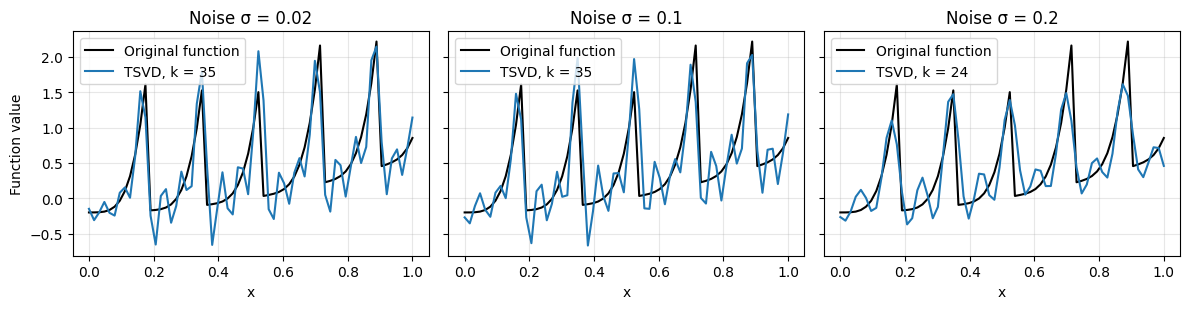

In [80]:
# Generate observations on a finer grid than the inversion model.
data_clean = np.convolve(fun(np.linspace(0, 1, 2*n)), psf, mode='same')[::2]
ground_truth = fun(xx)  # Used only for displaying the simulated example.
U, Svals, Vt = la.svd(A)

noise_levels = (0.02, 0.1, 0.2)
# Scale one noise realization to compare the three noise levels.
unit_noise = np.random.default_rng(123).standard_normal(n)
cutoffs = np.arange(1, n)  # k = n is excluded: the GCV denominator vanishes.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)

for ax, sigma in zip(axes, noise_levels):
    data_noisy = data_clean + sigma * unit_noise
    coefficients = U.T @ data_noisy
    # The omitted left-singular coefficients give the TSVD residual norm.
    residuals = np.array([la.norm(coefficients[k:]) for k in cutoffs])
    gcv = residuals**2 / (n - cutoffs)**2
    k_selected = int(cutoffs[np.argmin(gcv)])
    reconstruction = Vt[:k_selected, :].T @ (coefficients[:k_selected] / Svals[:k_selected])

    ax.plot(xx, ground_truth, 'k', label='Original function')
    ax.plot(xx, reconstruction, label=f'TSVD, k = {k_selected}')
    ax.set(xlabel='x', title=f'Noise σ = {sigma}')
    ax.grid(alpha=0.3)
    ax.legend()
    print(f'σ = {sigma:.2f}: selected k = {k_selected} ({100*k_selected/n:.0f}% of singular values)')

axes[0].set_ylabel('Function value')
fig.tight_layout()

**Result.** Generalized cross-validation selects **35 of 64** singular values at $\sigma=0.02$, **35 of 64** at $\sigma=0.1$, and **24 of 64** at $\sigma=0.2$. The highest noise level calls for stronger truncation. The two lower noise levels give the same cutoff here because model mismatch remains even as measurement noise decreases; the cutoff is therefore not expected to change monotonically for every finite noise realization. The original function in the plots is shown only to assess the reconstructions after selection.

___
## Task 4 (Convolution and its adjoint)

Given two (sufficiently well-behaving) functions $f,g: \mathbb{R}^d \to \mathbb{R}$, their convolution is defined as the linear integral operator
$$ f*g(x) := \int_{\mathbb{R}^d} f(y) g(x - y) dy.$$
Show that
1. $f * g = g * f$,
2. $f * (g * h) = (f * g) * h$,
3. $f * (g + h) = f * g + f * h$,
4. $\widehat{f * g} = \widehat{f} \, \widehat{g}$, where $\widehat{f}(\xi) = \int_{\mathbb{R}^d} f(x) e^{-2 \pi i x \cdot \xi} dx$ is the Fourier transform.

For a fixed sequence $g \in \ell^2(\mathbb{Z})$ (sometimes called the _convolution filter_ or _convolution kernel_), consider the operator $G: \ell^2(\mathbb{Z}) \to \ell^2(\mathbb{Z})$ defined as the following _discrete convolution_
$$ G(f) = f * g = \left( \sum_{i = -\infty}^\infty f_i g_{j - i} \right)_{j=-\infty}^\infty. $$
5. Find its adjoint $G^*$ and in particular, what is the filter of $G^*$?


### Solution

For parts 1–4, let $f,g,h\in L^1(\mathbb R^d)$. The integrals and changes of integration order below are then justified by Fubini's theorem, and the convolution identities hold almost everywhere.

**1. Commutativity.** With $z=x-y$,
$$
(f*g)(x)=\int_{\mathbb R^d} f(y)g(x-y)\,dy
=\int_{\mathbb R^d} g(z)f(x-z)\,dz=(g*f)(x).
$$

**2. Associativity.** Expanding the inner convolution and setting $t=y+z$ gives
$$
\begin{aligned}
[f*(g*h)](x)
&=\int_{\mathbb R^d}\int_{\mathbb R^d}f(y)g(z)h(x-y-z)\,dz\,dy\\
&=\int_{\mathbb R^d}\left[\int_{\mathbb R^d}f(y)g(t-y)\,dy\right]h(x-t)\,dt\\
&=[(f*g)*h](x).
\end{aligned}
$$

**3. Distributivity.** Linearity of the integral yields
$$
[f*(g+h)](x)=\int f(y)\bigl(g(x-y)+h(x-y)\bigr)\,dy
=(f*g)(x)+(f*h)(x).
$$

**4. Fourier transform.** Using the stated convention and substituting $z=x-y$,
$$
\begin{aligned}
\widehat{f*g}(\xi)
&=\int\!\int f(y)g(x-y)e^{-2\pi i x\cdot\xi}\,dy\,dx\\
&=\int\!\int f(y)g(z)e^{-2\pi i(y+z)\cdot\xi}\,dz\,dy
=\widehat f(\xi)\widehat g(\xi).
\end{aligned}
$$

**5. Adjoint of discrete convolution.** Use the complex $\ell^2$ inner product $\langle f,h\rangle=\sum_j f_j\overline{h_j}$, which is linear in the first argument (the real case is the same without conjugates). Reindexing $m=j-i$ gives
$$
\begin{aligned}
\langle Gf,h\rangle
&=\sum_j\sum_i f_i g_{j-i}\overline{h_j}\\
&=\sum_i f_i\overline{\left(\sum_m\overline{g_m}\,h_{i+m}\right)}.
\end{aligned}
$$
Hence
$$
(G^*h)_i=\sum_m\overline{g_m}\,h_{i+m}
=\sum_j h_j\overline{g_{j-i}}=(h*\widetilde g)_i,
\qquad \widetilde g_k=\overline{g_{-k}}.
$$
Thus the adjoint filter is the **reversed, complex-conjugated** filter; for the real sequences in this exercise, it is simply $\widetilde g_k=g_{-k}$.

Strictly, $g\in\ell^2$ alone does not ensure that convolution maps every $f\in\ell^2$ back into $\ell^2$. The calculation is valid for finitely supported $f$ and gives the adjoint formula whenever $G$ is bounded on $\ell^2$; for example, $g\in\ell^1$ is sufficient by $\|Gf\|_2\leq\|g\|_1\|f\|_2$. Under that condition the sums may be interchanged and $G^*$ is a bounded operator on $\ell^2$.